# Partie 1 : Donnees Mouse

Les dix dernieres observations du fichier sont considerees comme anomalies de reference uniquement pour l'evaluation. Le vecteur `y_reference` est construit avant toute operation de melange ou de partitionnement et n'est jamais fourni aux methodes non supervis?es.


In [1]:
from pathlib import Path
import platform
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from utils import fit_isolation_forest, fit_lof, load_mouse_data, plot_scores

SEED = 42
N_REFERENCE_OUTLIERS = 10
DATA_PATH = Path("mouse.txt")
np.random.seed(SEED)

print(f"Python : {platform.python_version()}")
print(f"NumPy : {np.__version__}")
print(f"pandas : {pd.__version__}")
print(f"scikit-learn : {sklearn.__version__}")


Python : 3.13.5
NumPy : 2.3.4
pandas : 2.3.3
scikit-learn : 1.7.2


## 1.a Chargement, verification et visualisation

Le fichier ne contient pas de cible. On crie donc `y_reference` a partir de sa position dans le fichier : `0` pour les observations normales et `1` pour les dix dernieres observations.


Dimensions de X : (500, 2)
Valeurs manquantes : 0
Nombre d'observations normales : 490
Nombre d'anomalies de référence : 10


,x1,x2
0,0.456601,0.432806
1,0.611378,0.528625
2,0.450299,0.711606
3,0.639015,0.460744
4,0.628957,0.323470


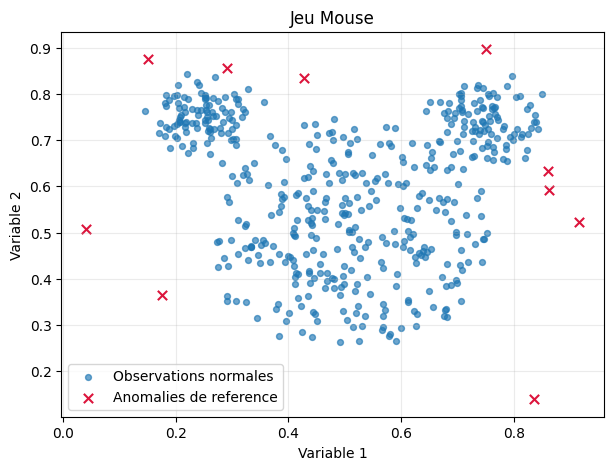

In [5]:
X, y_reference = load_mouse_data(DATA_PATH, n_reference_outliers=N_REFERENCE_OUTLIERS)

print(f"Dimensions de X : {X.shape}")
print(f"Valeurs manquantes : {np.isnan(X).sum()}")
print(f"Nombre d'observations normales : {(y_reference == 0).sum()}")
print(f"Nombre d'anomalies de référence : {(y_reference == 1).sum()}")
display(pd.DataFrame(X, columns=["x1", "x2"]).head())

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X[y_reference == 0, 0], X[y_reference == 0, 1], s=18, alpha=0.65, label="Observations normales")
ax.scatter(X[y_reference == 1, 0], X[y_reference == 1, 1], s=45, marker="x", color="crimson", label="Anomalies de reference")
ax.set(title="Jeu Mouse", xlabel="Variable 1", ylabel="Variable 2")
ax.legend()
ax.grid(alpha=0.25)
plt.show()


## 1.b : Isolation Forest et LOF

La contamination est fixee ? `10 / 500`, conformement au nombre d anomalies de reference. Les scores sont orientes de sorte qu une valeur elevee signifie une observation plus anormale.


In [8]:
contamination = N_REFERENCE_OUTLIERS / len(X)

t0 = time.perf_counter()
isolation_forest, if_labels, if_scores = fit_isolation_forest(X, contamination=contamination, random_state=SEED)
if_fit_time = time.perf_counter() - t0

t0 = time.perf_counter()
lof_train, lof_train_labels, lof_train_scores, lof_novelty, lof_novelty_scores = fit_lof(X, n_neighbors=20, contamination=contamination)
lof_fit_time = time.perf_counter() - t0

print(f"Isolation Forest : apprentissage + scores : {if_fit_time:.4f} s")
print(f"LOF : apprentissage + scores : {lof_fit_time:.4f} s")
print(f"Outliers detectes par Isolation Forest : {(if_labels == -1).sum()}")
print(f"Outliers detectes par LOF : {(lof_train_labels == -1).sum()}")


Isolation Forest : apprentissage + scores : 0.2523 s
LOF : apprentissage + scores : 0.0079 s
Outliers detectes par Isolation Forest : 10
Outliers detectes par LOF : 10


### Isolation Forest : points detectes, score et histogramme


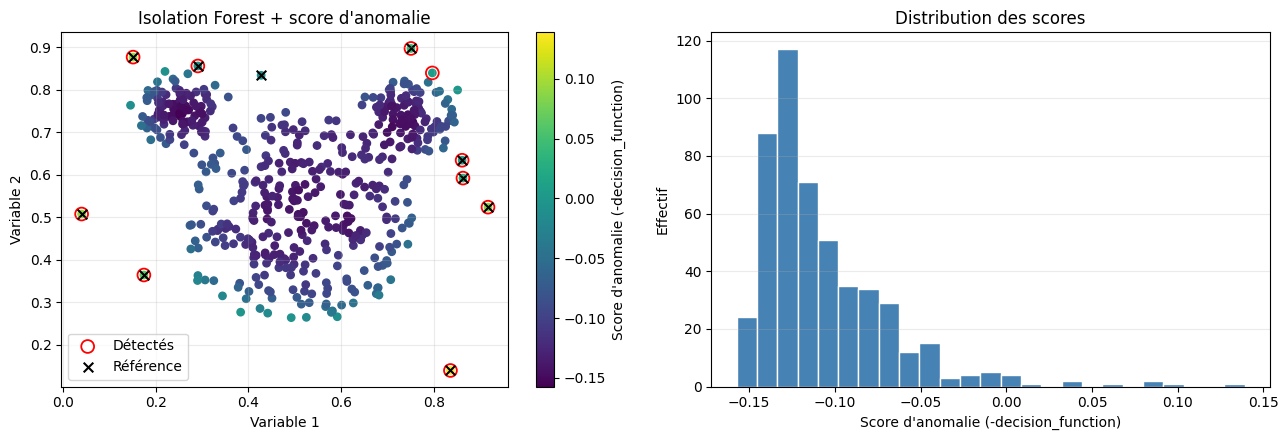

In [11]:
plot_scores(
    X, if_scores, if_labels,
    title="Isolation Forest + score d'anomalie",
    score_label="Score d'anomalie (-decision_function)",
    reference_labels=y_reference,
)


### LOF : score d'apprentissage et score de nouveaute

Avec `novelty=False` (usage transductif), LOF expose `negative_outlier_factor_` sur les observations utilisees pour l'apprentissage. Avec `novelty=True`, il faut ajuster un second modele et utiliser `score_samples` pour scorer de nouvelles observations. Ces deux scores ne sont pas definis exactement de la mme facon ; ils sont affiches separement.


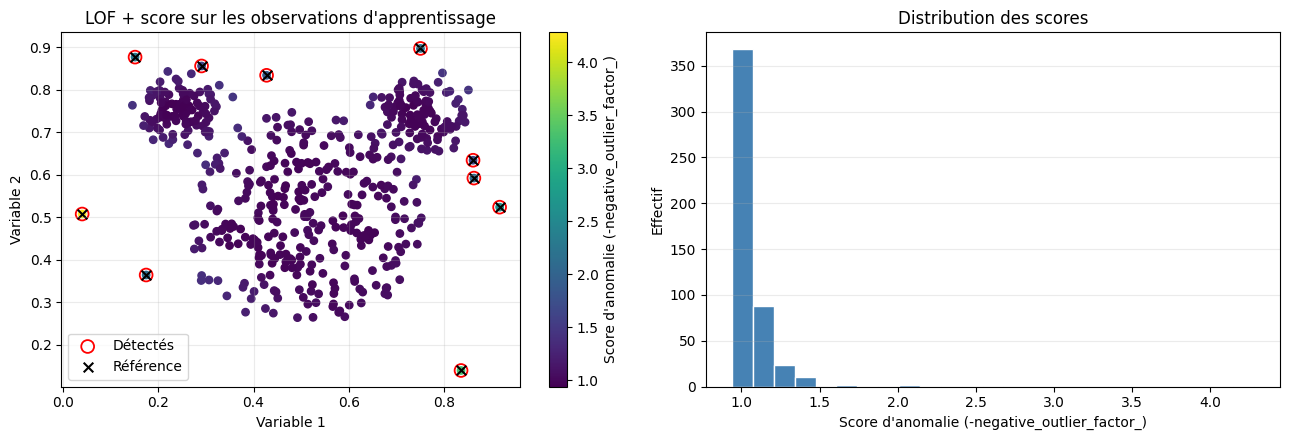

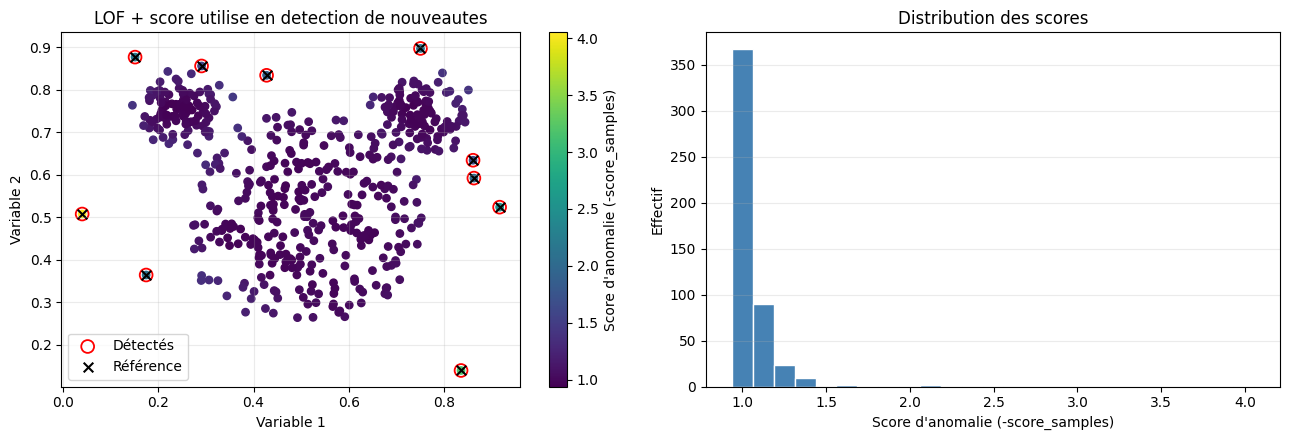

In [14]:
plot_scores(
    X, lof_train_scores, lof_train_labels,
    title="LOF + score sur les observations d'apprentissage",
    score_label="Score d'anomalie (-negative_outlier_factor_)",
    reference_labels=y_reference,
)

novelty_labels = np.where(
    lof_novelty_scores >= np.quantile(lof_novelty_scores, 1 - contamination), -1, 1
)
plot_scores(
    X, lof_novelty_scores, novelty_labels,
    title="LOF + score utilise en detection de nouveautes",
    score_label="Score d'anomalie (-score_samples)",
    reference_labels=y_reference,
)


In [17]:
summary = pd.DataFrame({
    "methode": ["Isolation Forest", "LOF (apprentissage)", "LOF (nouveaute)"],
    "temps_apprentissage_s": [if_fit_time, lof_fit_time, lof_fit_time],
    "nombre_outliers": [int((if_labels == -1).sum()), int((lof_train_labels == -1).sum()), int((novelty_labels == -1).sum())],
})
display(summary)
print("Les etiquettes de reference ont uniquement servi a distinguer visuellement les dix derniers points.")


,methode,temps_apprentissage_s,nombre_outliers
0,Isolation Forest,0.252261,10
1,LOF (apprentissage),0.007922,10
2,LOF (nouveaute),0.007922,10


Les etiquettes de reference ont uniquement servi a distinguer visuellement les dix derniers points.
